# Metamer-SAE — Notebook 01
## Environment setup and Feather repository audit

**Milestone 1 · Colab prototype · Phase 1**

This notebook establishes the working environment and audits the visual parts of Feather et al.'s `model_metamers_pytorch` repository.

### Current project decisions
- **Visual-only scope.** Inspect visual models and visual stimuli; audio components are excluded.
- **No human-recognition analysis for now.** Behavioural-data directories are deliberately not opened.
- **Use existing Feather source images and metamers first.** Metamer regeneration is not part of Notebook 01.
- **TopK SAE is the only planned primary SAE** for the initial experiment. Vanilla SAE and JumpReLU are deferred alternatives for a later experiment.
- The common observer will be selected in Phase 3, after the model/stimulus inventory.

### Notebook 01 outputs
1. Runtime and dependency report.
2. Feather repository clone and commit record.
3. Repository structure inventory.
4. Visual experiment/model catalogue.
5. Visual configuration and checkpoint inventory.
6. Local visual image/data inventory and image gallery, where files are present.
7. CSV/JSON audit outputs saved under `phase1_audit/`.

> Feather's README says the repository is not configured for `pip install`. It supplies older Conda environment files. We inspect those rather than blindly installing an old pinned Python/PyTorch/CUDA stack into modern Colab.

## Phase 1 workflow

```text
Colab runtime
    ↓
Clone / locate Feather repository
    ↓
Inspect README and dependency instructions
    ↓
Inspect visual model catalogue and configurations
    ↓
Inspect locally available visual checkpoints and stimuli
    ↓
Visualize repository structure and image samples
    ↓
Save audit report for Notebook 02
```

**Not included:** human behavioural data, human-recognition metrics, metamer regeneration, activation extraction, PCA or SAE training.

## 0. Runtime check

GPU is not required for this audit. If Colab provides one, its information is recorded for later phases.

In [ ]:
import os, sys, re, json, platform, subprocess, importlib.util, random, math
from pathlib import Path
from datetime import datetime, timezone

print("Python:", sys.version)
print("Platform:", platform.platform())
print("Working directory:", os.getcwd())

try:
    import torch
    print("PyTorch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print("VRAM (GiB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
except Exception as e:
    print("PyTorch import issue:", repr(e))

try:
    subprocess.run(["nvidia-smi"], check=False)
except FileNotFoundError:
    print("nvidia-smi unavailable.")

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
Working directory: /content
PyTorch: 2.14.1+cpu
CUDA available: False
nvidia-smi unavailable.


## 1. Configure paths — you do not need to supply an image folder yet

**For your first run, leave `EXTERNAL_VISUAL_DATA_DIR = None`.** You said you have not separately downloaded the image files, and that is perfectly fine.

There are three different locations/sources in this project:

1. **GitHub repository code:** the clone cell downloads the tracked code and model configuration files into `/content/model_metamers_pytorch`. This is automatic.
2. **Feather's large files:** pretrained visual checkpoints and base stimulus assets are hosted outside GitHub. The Git clone does not download them. We inspect whether they are present and only download a specific visual archive if needed.
3. **Published metamer example images:** Feather's visual-example notebook loads example PNGs directly from the McDermott Lab web server. We will add a remote preview below, so you can see examples without manually downloading a dataset.

`EXTERNAL_VISUAL_DATA_DIR` is only an optional path for files you have already placed somewhere else (for example, a visual-data folder in Google Drive). It is **not** a download setting.

The default working directory is `/content`, which is temporary Colab storage. It is not Google Drive. If the runtime disconnects or is reset, files stored only under `/content` can be lost. Later, we can copy selected data, activations and checkpoints to Drive for persistence.

In [ ]:
FEATHER_REPO_URL = "https://github.com/jenellefeather/model_metamers_pytorch.git"

# Git clone location in the current Colab runtime (temporary storage).
FEATHER_REPO_DIR = Path("/content/model_metamers_pytorch")

# Leave this as None for your first run.
# Only set it if you ALREADY have an additional visual dataset folder
# stored somewhere, e.g. /content/drive/MyDrive/FeatherVisualData.
EXTERNAL_VISUAL_DATA_DIR = None

WORK_DIR = Path("/content/metamer_sae_phase1")
OUTPUT_DIR = WORK_DIR / "phase1_audit"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Optional persistent location in Google Drive.
# Uncomment and run this if you want audit outputs to survive Colab resets.
#
# from google.colab import drive
# drive.mount("/content/drive")
# OUTPUT_DIR = Path("/content/drive/MyDrive/metamer-sae/phase1_audit")
# OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Remote sample images can be saved to this folder if the preview cell is run.
# By default this is also temporary Colab storage.
REMOTE_PREVIEW_DIR = OUTPUT_DIR / "remote_visual_metamer_preview"

print("Feather repository will be cloned to:", FEATHER_REPO_DIR)
print("External visual folder (optional):", EXTERNAL_VISUAL_DATA_DIR)
print("Audit outputs:", OUTPUT_DIR)
print("Remote preview images (if saved):", REMOTE_PREVIEW_DIR)

Feather repository will be cloned to: /content/model_metamers_pytorch
External visual folder (optional): None
Audit outputs: /content/metamer_sae_phase1/phase1_audit
Remote preview images (if saved): /content/metamer_sae_phase1/phase1_audit/remote_visual_metamer_preview


## 2. Clone Feather's repository

The Feather repository is not a pip-installable package. This cell shallow-clones it if it is absent. If the folder already exists, it leaves your checkout untouched.

In [ ]:
if not FEATHER_REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", FEATHER_REPO_URL, str(FEATHER_REPO_DIR)],
        check=True
    )
elif not (FEATHER_REPO_DIR / ".git").exists():
    raise RuntimeError(
        f"{FEATHER_REPO_DIR} exists but is not a Git repository. "
        "Please correct FEATHER_REPO_DIR."
    )
else:
    print("Existing Git clone found; not modifying it.")

commit = subprocess.check_output(
    ["git", "-C", str(FEATHER_REPO_DIR), "rev-parse", "HEAD"], text=True
).strip()
branch = subprocess.check_output(
    ["git", "-C", str(FEATHER_REPO_DIR), "branch", "--show-current"], text=True
).strip()
print("Commit:", commit)
print("Branch:", branch or "(detached HEAD)")

Commit: d9629b58ad43ce9a6bd74be951869cffbd8e8161
Branch: master


## 3. Install only lightweight audit dependencies if missing

Do not install Feather's full legacy environment in this notebook. We preserve the current Colab PyTorch/torchvision installation and add only common inspection/plotting packages if absent.

In [ ]:
import importlib.util

required = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "PIL": "pillow", "scipy": "scipy", "h5py": "h5py",
    "tqdm": "tqdm", "yaml": "pyyaml", "requests": "requests"
}
missing = [pkg for module, pkg in required.items()
           if importlib.util.find_spec(module) is None]
print("Missing packages:", missing or "None")

if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + missing)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import requests
from tqdm.auto import tqdm

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

Missing packages: None


## 4. Inspect Feather's README and downloader safely

The Git clone downloads the repository's tracked code and configuration files. It does **not** fetch the large assets hosted outside GitHub.

Feather's README identifies these external assets:
- Visual model checkpoints.
- Auditory model checkpoints.
- Base stimulus sets needed for metamer generation.
- Auditory fMRI data.

The helper script `download_large_files.py` downloads all three archives in sequence: visual checkpoints, audio checkpoints and a shared `assets/` archive. **Do not execute the complete helper script for this visual-only project.**

For your current first pass:
- We do not need the complete image dataset manually placed in Drive just to finish this audit.
- We can preview published visual metamer examples directly from Feather's web server.
- We will separately determine whether the visual checkpoint archive is needed for loading generator models.
- The shared base-stimulus archive is relevant if we later need to generate new metamers; it is not the same thing as the already-generated metamer PNGs.

Feather's model-analysis README also states that the per-model `metamers/` folders are represented in the repository structure, but the PNG and `.pckl` metamer files are omitted from GitHub because of their size. Its visual-example notebook retrieves example PNGs from the lab server instead. <https://github.com/jenellefeather/model_metamers_pytorch/blob/master/README.md>

In [ ]:
readme = (FEATHER_REPO_DIR / "README.md").read_text(encoding="utf-8", errors="replace")
for term in ["not set up for pip installation", "Downloading Assets",
             "15GB", "Metamer generation from the command line",
             "Null distribution generation"]:
    idx = readme.lower().find(term.lower())
    print("\\n" + "="*80 + "\\nSEARCH:", term, "| found:", idx >= 0)
    if idx >= 0:
        print(readme[max(0, idx-180):idx+650])

downloader = FEATHER_REPO_DIR / "download_large_files.py"
if downloader.exists():
    print("\\n--- download_large_files.py (inspection only; NOT executed) ---")
    print(downloader.read_text(encoding="utf-8", errors="replace"))

\n================================================================================\nSEARCH: not set up for pip installation | found: True
es are no longer available from the original file).  
`yml_files_for_dependencies/feather_metamers_conda_2023_updated_for_new_model_requirements.yml`

Currently, the repository is not set up for pip installation.

ANOVA statistics were performed in MATLAB 2021a (not included in the conda installation). 

## Downloading Assets
Some files are too large for uploading to github and are hosted elsewhere. A helper script is included for downloading. 
* Visual model checkpoints
* Auditory model checkpoints
* Base stimulus sets necessary for metamer generation
* Auditory fMRI data

The helper script can be run with `python download_large_files.py`. Note: Downloading all of the assets will take ~15GB of storage! If you only need some of the files, only run the necessary lines from `download_large_files.py`. 

## Testing Environ
\n=============================

### 4.1 Asset-download decision

The current helper script includes:
- visual checkpoint archive (about 5.5 GB);
- audio checkpoint archive (about 9.4 GB);
- shared assets archive (about 366 MB).

Notebook 01 will not download any of these automatically. First inspect whether the required files are already present. If the visual checkpoints are missing, decide separately whether to download the visual archive only. Do not download audio checkpoints for this visual project.

## 5. Repository structure inventory

We inspect the repository layout and visualize the top-level directory structure. The human behavioural-data folders are deliberately excluded from deep inspection.

,name,type,immediate_files,immediate_subdirectories
0,analysis_scripts,directory,19,0
1,assets,directory,1,0
2,AuditoryBehavioralExperiments,directory,4,6
3,download_large_files.py,file,1,0
4,feather_metamers_conda_2022.yml,file,1,0
5,FigureExperimentLogic.png,file,1,0
6,LICENSE,file,1,0
7,matlab_statistics_functions,directory,9,0
8,model_analysis_folders,directory,4,2
9,notebooks,directory,11,0


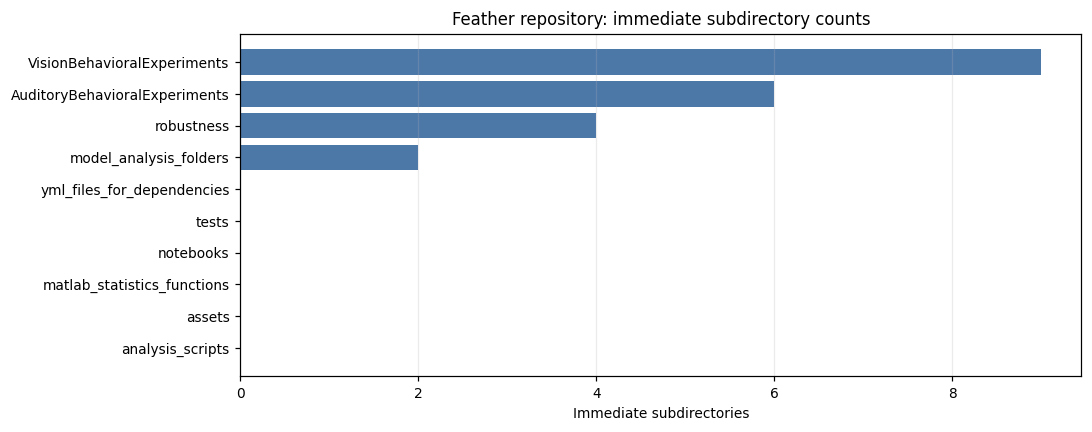

In [ ]:
EXCLUDED_DIRS = {".git", "VisionBehavioralExperiments",
                 "AuditoryBehavioralExperiments", "__pycache__"}

rows = []
for p in sorted(FEATHER_REPO_DIR.iterdir(), key=lambda x: x.name.lower()):
    if p.name == ".git":
        continue
    if p.is_dir():
        children = list(p.iterdir())
        rows.append({
            "name": p.name, "type": "directory",
            "immediate_files": sum(x.is_file() for x in children),
            "immediate_subdirectories": sum(x.is_dir() for x in children)
        })
    else:
        rows.append({"name": p.name, "type": "file",
                     "immediate_files": 1, "immediate_subdirectories": 0})

repo_top_df = pd.DataFrame(rows)
display(repo_top_df)

plot_df = repo_top_df[repo_top_df.type == "directory"].sort_values("immediate_subdirectories")
if not plot_df.empty:
    fig, ax = plt.subplots(figsize=(10, max(4, len(plot_df)*0.35)))
    ax.barh(plot_df.name, plot_df.immediate_subdirectories, color="#4C78A8")
    ax.set_title("Feather repository: immediate subdirectory counts")
    ax.set_xlabel("Immediate subdirectories")
    ax.grid(axis="x", alpha=.25)
    plt.tight_layout()
    plt.show()

## 6. Catalogue Feather's visual model/experiment groups

We read `model_analysis_folders/all_model_info.py` as text and extract only the **visual experiment grouping names and listed visual network names**. We do not import the file and do not load behavioural data.

The catalogue is useful for locating standard/adversarial ResNet50, AlexNet and IPCL model variants. It is not proof that every associated checkpoint or metamer file is downloaded locally.

,feather_experiment,paper_group,visual_networks,n_networks
0,experiment_1,Visual Experiment 1 (Standard Models),"cornet_s, alexnet, vgg_19, resnet50, resnet101",5
1,experiment_3,Visual Experiment 7 (ResNet50 Adversarially Ro...,"resnet50, resnet50_l2_3_robust, resnet50_linf_...",6
2,experiment_4,Visual Experiment 8 (AlexNet Adversarially Rob...,"alexnet, alexnet_l2_3_robust, alexnet_random_l...",5
3,experiment_5,Visual Experiment 3 (Self-Supervised Models),"resnet50, resnet50_simclr, resnet50_moco_v2, r...",4
4,experiment_6,Visual Experiment 6 (HMAX),hmax_standard,1
5,experiment_9,Visual Experiment 12 (Lowpass AlexNet and VOne...,"alexnet_early_checkpoint, alexnet_reduced_alia...",3
6,experiment_10,Visual Experiment 5 (Stylized-ImageNet Trained...,"resnet50, texture_shape_resnet50_trained_on_SI...",4
7,experiment_12,Visual Experiment 2 (Large-Scale Dataset Models),"CLIP_resnet50, CLIP_ViT-B_32, SWSL_resnet50, S...",5
8,experiment_16,Visual Experiment 4 (IPCL AlexNetGN),"konkle_alexnetgn_ipcl_ref01_primary_model, kon...",2


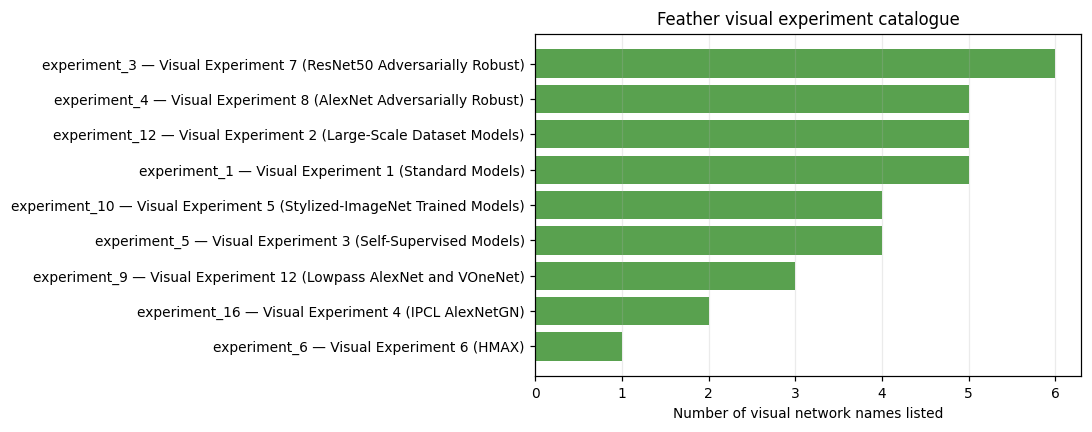

In [ ]:
model_info_path = FEATHER_REPO_DIR / "model_analysis_folders" / "all_model_info.py"
visual_experiment_rows = []

if not model_info_path.exists():
    print("Model catalogue file not found:", model_info_path)
else:
    info = model_info_path.read_text(encoding="utf-8", errors="replace")

    # Restrict parsing to the visual experiment grouping dictionary.
    visual_start = info.find("TURK_IMAGE_EXPERIMENTS_GROUPINGS")
    audio_start = info.find("TURK_AUDIO_EXPERIMENTS_GROUPINGS")

    if visual_start < 0:
        raise RuntimeError("Could not locate TURK_IMAGE_EXPERIMENTS_GROUPINGS.")
    visual_text = info[visual_start:audio_start] if audio_start > visual_start else info[visual_start:]

    # IMPORTANT: use \d (one escaped regex token) to match experiment numbers.
    starts = list(re.finditer(r"'(experiment_\d+)'\s*:\s*\{", visual_text))

    for i, match in enumerate(starts):
        block_start = match.end()
        block_end = starts[i + 1].start() if i + 1 < len(starts) else len(visual_text)
        block = visual_text[block_start:block_end]

        network_match = re.search(r"'networks'\s*:\s*\[(.*?)\]", block, flags=re.DOTALL)
        networks = re.findall(r"'([^']+)'", network_match.group(1)) if network_match else []

        paper_match = re.search(r"'paper_experiment_name'\s*:\s*'([^']+)'", block)
        paper_name = paper_match.group(1) if paper_match else ""

        visual_experiment_rows.append({
            "feather_experiment": match.group(1),
            "paper_group": paper_name,
            "visual_networks": ", ".join(networks),
            "n_networks": len(networks)
        })

visual_experiment_df = pd.DataFrame(visual_experiment_rows)
display(visual_experiment_df)

if visual_experiment_df.empty:
    print("No visual experiment groups were parsed. Check the catalogue file and parser.")
else:
    visual_experiment_df.to_csv(
        OUTPUT_DIR / "feather_visual_experiment_catalogue.csv",
        index=False
    )

    tmp = visual_experiment_df.sort_values("n_networks")
    fig, ax = plt.subplots(figsize=(10, max(4, 0.42 * len(tmp))))
    ax.barh(tmp.feather_experiment + " — " + tmp.paper_group,
            tmp.n_networks, color="#59A14F")
    ax.set_xlabel("Number of visual network names listed")
    ax.set_title("Feather visual experiment catalogue")
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()

## 7. Locate visual model configuration folders

Feather's README and scripts refer to `model_analysis_folders/visual_networks/`; some examples in the repository documentation use `visual_models/`. This notebook checks both paths instead of assuming one spelling.

For each model directory, it records whether `build_network.py` and `pytorch_checkpoints/` are present.

In [ ]:
visual_root_candidates = [
    FEATHER_REPO_DIR / "model_analysis_folders" / "visual_networks",
    FEATHER_REPO_DIR / "model_analysis_folders" / "visual_models",
]
visual_roots = [p for p in visual_root_candidates if p.exists()]

print("Visual roots found:")
for p in visual_roots:
    print(" -", p)

model_rows = []
for root in visual_roots:
    for model_dir in sorted([p for p in root.iterdir() if p.is_dir()]):
        # This is a shared checkpoint-storage folder, not a model configuration.
        if model_dir.name == "pytorch_checkpoints":
            continue

        configs = (
            list(model_dir.glob("*.py"))
            + list(model_dir.glob("*.yaml"))
            + list(model_dir.glob("*.yml"))
        )

        role = (
            "template_placeholder"
            if model_dir.name == "example_blank_directory"
            else "model_configuration"
        )

        model_rows.append({
            "visual_root": str(root.relative_to(FEATHER_REPO_DIR)),
            "model_directory": model_dir.name,
            "directory_role": role,
            "build_network_py": (model_dir / "build_network.py").exists(),
            "pytorch_checkpoints_dir": (model_dir / "pytorch_checkpoints").exists(),
            "n_top_level_config_files": len(configs),
            "config_files": ", ".join(p.name for p in configs[:10])
        })

visual_model_dirs_df = pd.DataFrame(model_rows)
display(
    visual_model_dirs_df if not visual_model_dirs_df.empty else
    pd.DataFrame({"status":["No visual model configuration directories found at the candidate paths."]})
)
visual_model_dirs_df.to_csv(
    OUTPUT_DIR / "visual_model_directory_inventory.csv",
    index=False
)

if not visual_model_dirs_df.empty:
    print(
        "Model configuration directories:",
        int((visual_model_dirs_df["directory_role"] == "model_configuration").sum())
    )
    print(
        "Template placeholders:",
        int((visual_model_dirs_df["directory_role"] == "template_placeholder").sum())
    )

Visual roots found:
 - /content/model_metamers_pytorch/model_analysis_folders/visual_networks


,visual_root,model_directory,directory_role,build_network_py,pytorch_checkpoints_dir,n_top_level_config_files,config_files
0,model_analysis_folders/visual_networks,CLIP_ViT-B_32,model_configuration,True,False,2,"imagenet_info_clip.py, build_network.py"
1,model_analysis_folders/visual_networks,CLIP_resnet50,model_configuration,True,False,2,"imagenet_info_clip.py, build_network.py"
2,model_analysis_folders/visual_networks,SWSL_resnet50,model_configuration,True,False,1,build_network.py
3,model_analysis_folders/visual_networks,SWSL_resnext101_32x8d,model_configuration,True,False,1,build_network.py
4,model_analysis_folders/visual_networks,alexnet,model_configuration,True,False,2,"build_network.py, __init__.py"
5,model_analysis_folders/visual_networks,alexnet_early_checkpoint,model_configuration,True,False,2,"build_network.py, __init__.py"
6,model_analysis_folders/visual_networks,alexnet_l2_3_robust,model_configuration,True,False,2,"build_network.py, __init__.py"
7,model_analysis_folders/visual_networks,alexnet_linf_8_robust,model_configuration,True,False,2,"build_network.py, __init__.py"
8,model_analysis_folders/visual_networks,alexnet_random_l2_3_perturb,model_configuration,True,False,2,"build_network.py, __init__.py"
9,model_analysis_folders/visual_networks,alexnet_random_linf8_perturb,model_configuration,True,False,2,"build_network.py, __init__.py"


Model configuration directories: 30
Template placeholders: 1


## 8. Inspect `build_network.py` configuration lines

We inspect relevant configuration lines without instantiating any model. Model loading and layer-hook verification belong in the next phase once the correct config/checkpoint pair has been chosen.

In [ ]:
hits = []
pattern = re.compile(
    r"checkpoint|state_dict|weights|model_path|model_name|architecture|arch|"
    r"layer|layers|all_outputs|preprocess|transform",
    re.I
)

for root in visual_roots:
    for bf in root.rglob("build_network.py"):
        lines = bf.read_text(encoding="utf-8", errors="replace").splitlines()
        matched = [(i+1, line.strip()) for i, line in enumerate(lines) if pattern.search(line)]
        for line_no, line in matched[:25]:
            hits.append({
                "model_directory": bf.parent.name,
                "file": str(bf.relative_to(FEATHER_REPO_DIR)),
                "line": line_no,
                "config_line": line[:220]
            })

config_hits_df = pd.DataFrame(hits)
display(config_hits_df.head(120) if not config_hits_df.empty else
        pd.DataFrame({"status":["No build_network.py files found under detected visual roots."]}))
config_hits_df.to_csv(OUTPUT_DIR / "visual_build_network_config_hits.csv", index=False)

# Focused view of the model configurations relevant to the first experiment
priority_models = [
    "resnet50",
    "resnet50_l2_3_robust",
    "alexnet",
    "alexnet_l2_3_robust",
    "konkle_alexnetgn_ipcl_ref01_primary_model",
    "konkle_alexnetgn_ipcl_ref12_supervised_ipcl_aug",
]
priority_config_hits_df = config_hits_df[
    config_hits_df["model_directory"].isin(priority_models)
].copy()

print("Focused configuration lines for the planned visual model families:")
display(priority_config_hits_df)


,model_directory,file,line,config_line
0,resnet50_linf_8_robust,model_analysis_folders/visual_networks/resnet5...,8,"def build_net(ds_kwargs={}, return_metamer_lay..."
1,resnet50_linf_8_robust,model_analysis_folders/visual_networks/resnet5...,12,# Resnet50 Layers Used for Metamer Generation
2,resnet50_linf_8_robust,model_analysis_folders/visual_networks/resnet5...,13,metamer_layers = [
3,resnet50_linf_8_robust,model_analysis_folders/visual_networks/resnet5...,17,"'layer1',"
4,resnet50_linf_8_robust,model_analysis_folders/visual_networks/resnet5...,18,"'layer1_fake_relu',"
...,...,...,...,...
115,resnet50_l2_3_robust,model_analysis_folders/visual_networks/resnet5...,18,"'layer1_fake_relu',"
116,resnet50_l2_3_robust,model_analysis_folders/visual_networks/resnet5...,19,"# 'layer2',"
117,resnet50_l2_3_robust,model_analysis_folders/visual_networks/resnet5...,20,"'layer2_fake_relu',"
118,resnet50_l2_3_robust,model_analysis_folders/visual_networks/resnet5...,21,"# 'layer3',"


Focused configuration lines for the planned visual model families:


,model_directory,file,line,config_line
23,alexnet,model_analysis_folders/visual_networks/alexnet...,7,"def build_net(ds_kwargs={}, return_metamer_lay..."
24,alexnet,model_analysis_folders/visual_networks/alexnet...,11,# Resnet50 Layers Used for Metamer Generation
25,alexnet,model_analysis_folders/visual_networks/alexnet...,12,metamer_layers = [
26,alexnet,model_analysis_folders/visual_networks/alexnet...,33,"model, _ = make_and_restore_model(arch='alexne..."
27,alexnet,model_analysis_folders/visual_networks/alexnet...,40,if return_metamer_layers:
...,...,...,...,...
397,resnet50,model_analysis_folders/visual_networks/resnet5...,43,if return_metamer_layers:
398,resnet50,model_analysis_folders/visual_networks/resnet5...,44,"model, ds, metamer_layers = build_net("
399,resnet50,model_analysis_folders/visual_networks/resnet5...,45,"return_metamer_layers=return_metamer_layers,"
400,resnet50,model_analysis_folders/visual_networks/resnet5...,47,"return model, ds, metamer_layers"


## 9. Inventory locally available visual checkpoints

This cell looks only under the detected visual model roots. It does not download files and does not inspect behavioural folders.

In [ ]:
CHECKPOINT_SUFFIXES = {".pt", ".pth", ".ckpt", ".tar", ".pkl", ".pickle"}
ckpt_rows = []

for root in visual_roots:
    for p in root.rglob("*"):
        if p.is_file() and p.suffix.lower() in CHECKPOINT_SUFFIXES:
            ckpt_rows.append({
                "path": str(p.relative_to(FEATHER_REPO_DIR)),
                "filename": p.name,
                "suffix": p.suffix.lower(),
                "size_mb": round(p.stat().st_size / (1024**2), 2)
            })

checkpoint_df = pd.DataFrame(ckpt_rows)
display(checkpoint_df.head(100) if not checkpoint_df.empty else
        pd.DataFrame({"status":["No local visual checkpoint files found. The checkpoint archive may not yet be extracted."]}))
checkpoint_df.to_csv(OUTPUT_DIR / "visual_checkpoint_inventory.csv", index=False)

if not checkpoint_df.empty:
    tmp = checkpoint_df.nlargest(20, "size_mb").sort_values("size_mb")
    fig, ax = plt.subplots(figsize=(10, max(4, len(tmp)*.30)))
    ax.barh(tmp.filename, tmp.size_mb, color="#F28E2B")
    ax.set_xlabel("Size (MB)")
    ax.set_title("Largest locally available visual checkpoint files")
    ax.grid(axis="x", alpha=.25)
    plt.tight_layout()
    plt.show()

,status
0,No local visual checkpoint files found. The ch...


## 10. Inventory local visual image, tensor and array assets

This is a **local-file inventory only**. It checks:
- Feather's local `assets/` folder, if present;
- visual model configuration folders;
- repository notebooks;
- `EXTERNAL_VISUAL_DATA_DIR`, but only if you have supplied a path.

Since you have not separately downloaded the visual images, it is normal if this scan finds few or no local PNG/JPG files. It does **not** mean the Feather visual examples are unavailable. The next section previews selected published metamer examples directly from Feather's web server.

You do not need to change `EXTERNAL_VISUAL_DATA_DIR` for this.

In [ ]:
IMAGE_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
ARRAY_EXT = {".npy", ".npz", ".h5", ".hdf5", ".mat"}
DATA_EXT = IMAGE_EXT | ARRAY_EXT | CHECKPOINT_SUFFIXES

scan_roots = []
for p in [
    FEATHER_REPO_DIR / "assets",
    FEATHER_REPO_DIR / "model_analysis_folders",
    FEATHER_REPO_DIR / "notebooks",
]:
    if p.exists():
        scan_roots.append(p)

if EXTERNAL_VISUAL_DATA_DIR is not None:
    ext = Path(EXTERNAL_VISUAL_DATA_DIR)
    if ext.exists():
        scan_roots.append(ext)
    else:
        print("WARNING: external data directory does not exist:", ext)

file_rows = []
MAX_FILES_PER_ROOT = 100000

for root in scan_roots:
    n_seen = 0
    for current, dirs, files in os.walk(root):
        dirs[:] = [d for d in dirs if d not in EXCLUDED_DIRS]
        for name in files:
            p = Path(current) / name
            if p.suffix.lower() in DATA_EXT:
                try:
                    size_mb = p.stat().st_size / (1024**2)
                except OSError:
                    size_mb = float("nan")
                typ = ("image" if p.suffix.lower() in IMAGE_EXT else
                       "array_or_data" if p.suffix.lower() in ARRAY_EXT else
                       "checkpoint_or_archive")
                file_rows.append({
                    "path": str(p), "suffix": p.suffix.lower(),
                    "file_type": typ, "size_mb": round(size_mb, 3)
                })
            n_seen += 1
            if n_seen >= MAX_FILES_PER_ROOT:
                print("Scan cap reached for:", root)
                break
        if n_seen >= MAX_FILES_PER_ROOT:
            break

file_inventory_df = pd.DataFrame(file_rows)
display(file_inventory_df.head(100) if not file_inventory_df.empty else
        pd.DataFrame({"status":["No matching local visual image/array/checkpoint files found in scanned locations."]}))
file_inventory_df.to_csv(OUTPUT_DIR / "visual_relevant_file_inventory.csv", index=False)

,path,suffix,file_type,size_mb
0,/content/model_metamers_pytorch/model_analysis...,.mat,array_or_data,9.182


,file_type,suffix,n_files
0,array_or_data,.mat,1


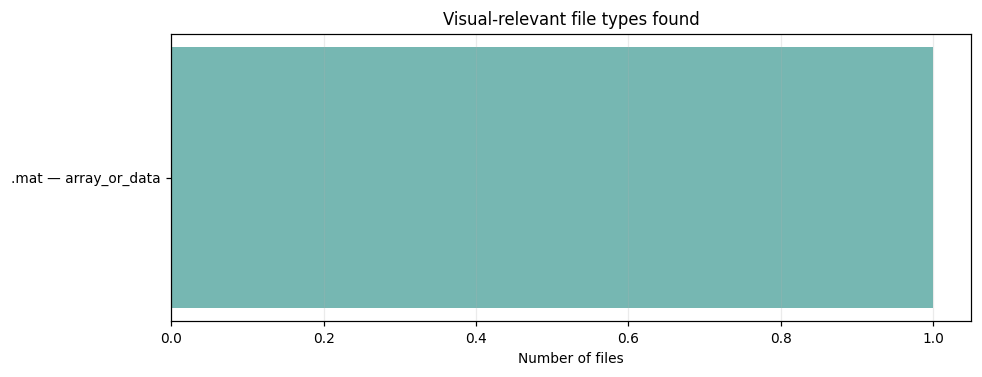

In [ ]:
if not file_inventory_df.empty:
    counts = (file_inventory_df.groupby(["file_type", "suffix"])
              .size().reset_index(name="n_files").sort_values("n_files"))
    display(counts)
    fig, ax = plt.subplots(figsize=(9, max(3.5, .35*len(counts))))
    ax.barh(counts["suffix"] + " — " + counts["file_type"],
            counts["n_files"], color="#76B7B2")
    ax.set_xlabel("Number of files")
    ax.set_title("Visual-relevant file types found")
    ax.grid(axis="x", alpha=.25)
    plt.tight_layout()
    plt.show()

## 11. Local image gallery (optional) and published Feather remote preview

First, the local gallery displays any image files that were actually found under the scanned folders. It may be empty on your first run.

Then the next section retrieves a small example directly from Feather's published visual metamer server. This is based on Feather's `VisualExperimentsViewMetamers.ipynb` and `notebook_helpers.py`.

**Important distinction:** remote preview downloads image bytes temporarily into the Colab Python process for display. The new cell can optionally save just the preview images under `REMOTE_PREVIEW_DIR`. It does not download all 400 stimuli or the full metamer collection.

In [ ]:
import matplotlib.pyplot as plt

image_paths = []
if not file_inventory_df.empty:
    image_paths = file_inventory_df.loc[
        file_inventory_df.file_type == "image", "path"
    ].drop_duplicates().tolist()

random.Random(17).shuffle(image_paths)
sample_paths = image_paths[:16]

def show_local_gallery(paths, ncols=4):
    if not paths:
        print(
            "No local image files were found. That is expected if you have not "
            "downloaded Feather's external visual assets yet. Continue to the "
            "remote preview section below; EXTERNAL_VISUAL_DATA_DIR can remain None."
        )
        return None

    nrows = math.ceil(len(paths) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3.2*nrows))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    for ax, path in zip(axes, paths):
        try:
            im = Image.open(path).convert("RGB")
            im.thumbnail((240, 180))
            ax.imshow(im)
            ax.set_title(Path(path).name[:32], fontsize=8)
            ax.set_xlabel(str(Path(path).parent)[-55:], fontsize=6)
        except Exception:
            ax.text(.5, .5, "Could not open", ha="center", va="center")
            ax.set_title(Path(path).name[:32], fontsize=7)
    fig.suptitle("Locally available visual images", fontsize=14)
    plt.tight_layout()
    plt.show()
    return fig

local_gallery_fig = show_local_gallery(sample_paths)

if local_gallery_fig is not None:
    local_gallery_fig.savefig(
        OUTPUT_DIR / "phase1_local_image_gallery.png",
        dpi=160, bbox_inches="tight"
    )

No local image files were found. That is expected if you have not downloaded Feather's external visual assets yet. Continue to the remote preview section below; EXTERNAL_VISUAL_DATA_DIR can remain None.


### 11.1 Preview existing Feather visual metamers directly from the web

Feather's published visual-example notebook fetches example images from the McDermott Lab server. This lets you inspect the reference image and existing generated metamers without first downloading the complete metamer folders.

The initial preview targets:
- standard ResNet50 from visual experiment 1 (`experiment_1`);
- adversarially trained ResNet50 from visual experiment 3 (`experiment_3`).

We request one common example index and one intermediate layer. If that index is missing for a condition, change `EXAMPLE_IMAGE_INDEX` and rerun. Feather notes that some images may be absent from a condition when they did not pass the original optimization criteria.

This preview does **not** open human behavioural data.

Retrieved: Standard ResNet50 | https://mcdermottlab.mit.edu/mturk_stimuli/imagerec_robust_models_v1/experiment_images/4_resnet50/2_layer2_fake_relu/0_resnet50_layer2_fake_relu.png
Retrieved: Adversarial ResNet50 | https://mcdermottlab.mit.edu/mturk_stimuli/imagerec_robust_models_v1/experiment3_images/2_resnet50_l2_3_robust/2_layer2_fake_relu/0_resnet50_l2_3_robust_layer2_fake_relu.png
Saved preview image: /content/metamer_sae_phase1/phase1_audit/remote_visual_metamer_preview/source.png
Saved preview image: /content/metamer_sae_phase1/phase1_audit/remote_visual_metamer_preview/resnet50_layer2_fake_relu_idx0.png
Saved preview image: /content/metamer_sae_phase1/phase1_audit/remote_visual_metamer_preview/resnet50_l2_3_robust_layer2_fake_relu_idx0.png


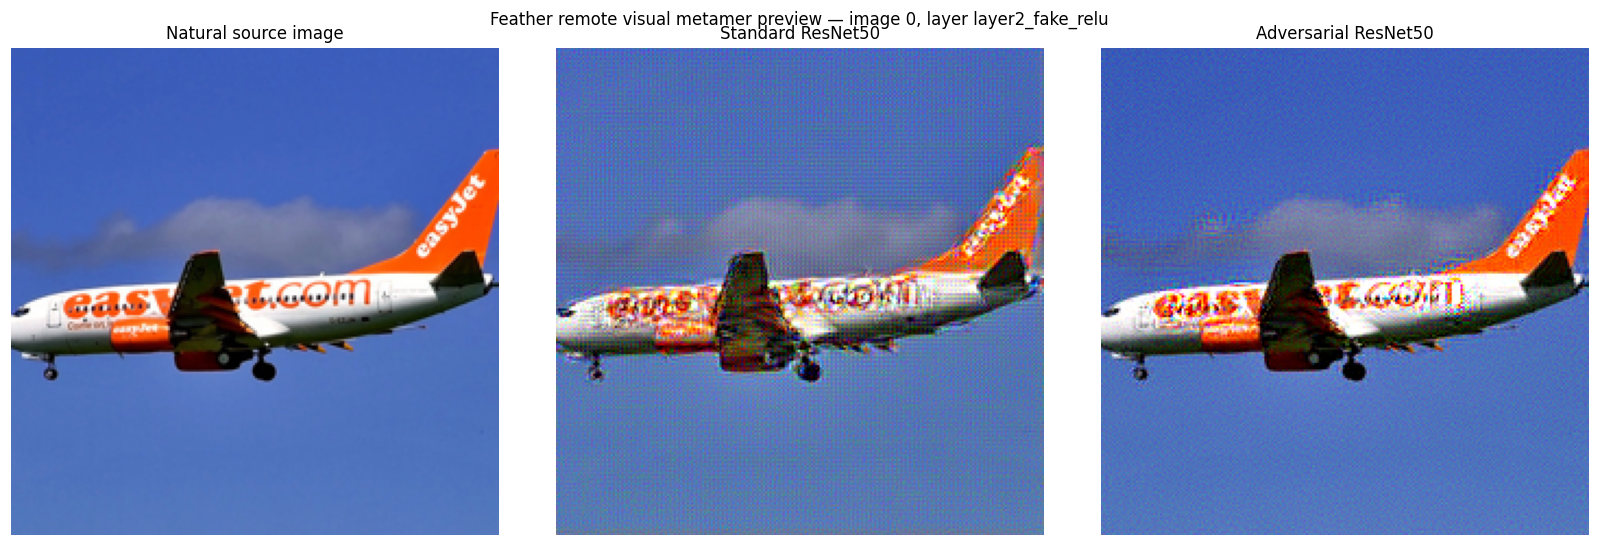

In [ ]:
import subprocess
import sys

# Install missing dependencies resampy, cox, and tensorboardX, which are required by the repository's audio helper utilities
# and robustness packages loaded during the import of all_model_info.
for pkg in ["resampy", "cox", "tensorboardX"]:
    try:
        __import__(pkg if pkg != "tensorboardX" else "tensorboardX")
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

from urllib.request import urlopen
from urllib.error import HTTPError, URLError
from io import BytesIO
from PIL import Image
import matplotlib.pyplot as plt
import json

# Import Feather's visual model metadata. This is model/stimulus metadata,
# not human behavioural data.
if str(FEATHER_REPO_DIR) not in sys.path:
    sys.path.insert(0, str(FEATHER_REPO_DIR))

from model_analysis_folders import all_model_info

EXAMPLE_IMAGE_INDEX = 0
EXAMPLE_LAYER = "layer2_fake_relu"

# If True, save only the few preview images retrieved by this cell.
# These are saved under /content/metamer_sae_phase1 by default.
SAVE_REMOTE_PREVIEW_IMAGES = True

# If you mounted Drive and want persistent copies, replace this with e.g.:
# REMOTE_PREVIEW_DIR = Path("/content/drive/MyDrive/metamer-sae/phase1_remote_preview")
if SAVE_REMOTE_PREVIEW_IMAGES:
    REMOTE_PREVIEW_DIR.mkdir(parents=True, exist_ok=True)

def read_remote_json(url):
    with urlopen(url, timeout=40) as response:
        return json.loads(response.read().decode("utf-8"))

def read_remote_image(url):
    with urlopen(url, timeout=40) as response:
        data = response.read()
    return Image.open(BytesIO(data)).convert("RGB"), data

def get_feather_visual_urls(experiment_key, network_key, layer_name, image_idx):
    exp = all_model_info.TURK_IMAGE_EXPERIMENTS_GROUPINGS[experiment_key]
    experiment_params = read_remote_json(exp["experiment_params_web"])
    network_order = experiment_params["experiment_info"]["networks"]

    if network_key not in network_order:
        raise ValueError(
            f"{network_key} is not listed for {experiment_key}. "
            f"Available networks: {network_order}"
        )

    model_idx = network_order.index(network_key)
    layers = all_model_info.ALL_NETWORKS_AND_LAYERS_IMAGES[network_key]["layers"]
    layers = [layer for layer in layers if "input_after_preproc" not in layer]

    if layer_name not in layers:
        raise ValueError(
            f"{layer_name} is not a metamer display layer for {network_key}. "
            f"Available layers: {layers}"
        )

    layer_idx = layers.index(layer_name)
    base = exp["experiment_folder_web"].rstrip("/")

    source_url = (
        f"{base}/0_orig/0_orig/"
        f"{image_idx}_orig_orig.png"
    )
    metamer_url = (
        f"{base}/{model_idx+1}_{network_key}/"
        f"{layer_idx}_{layer_name}/"
        f"{image_idx}_{network_key}_{layer_name}.png"
    )
    return source_url, metamer_url

preview_specs = [
    {
        "label": "Standard ResNet50",
        "experiment_key": "experiment_1",
        "network_key": "resnet50",
        "layer": EXAMPLE_LAYER
    },
    {
        "label": "Adversarial ResNet50",
        "experiment_key": "experiment_3",
        "network_key": "resnet50_l2_3_robust",
        "layer": EXAMPLE_LAYER
    }
]

# The source image URL is shared by the two visual experiments.
source_url, _ = get_feather_visual_urls(
    "experiment_1", "resnet50", EXAMPLE_LAYER, EXAMPLE_IMAGE_INDEX
)

preview_items = []
try:
    source_img, source_bytes = read_remote_image(source_url)
    preview_items.append(("Natural source image", source_img, source_bytes, "source.png"))
except Exception as exc:
    print("Could not retrieve the source image:", repr(exc))

for spec in preview_specs:
    try:
        _, metamer_url = get_feather_visual_urls(
            spec["experiment_key"], spec["network_key"],
            spec["layer"], EXAMPLE_IMAGE_INDEX
        )
        metamer_img, metamer_bytes = read_remote_image(metamer_url)
        filename = (
            f"{spec['network_key']}_{spec['layer']}_"
            f"idx{EXAMPLE_IMAGE_INDEX}.png"
        )
        preview_items.append((spec["label"], metamer_img, metamer_bytes, filename))
        print("Retrieved:", spec["label"], "|", metamer_url)
    except (HTTPError, URLError, ValueError, KeyError) as exc:
        print(
            f"Could not retrieve {spec['label']} for image index "
            f"{EXAMPLE_IMAGE_INDEX}: {exc}"
        )
        print("Try a different EXAMPLE_IMAGE_INDEX or inspect Feather's viewer notebook.")

if preview_items:
    fig, axes = plt.subplots(1, len(preview_items),
                             figsize=(5*len(preview_items), 5))
    if len(preview_items) == 1:
        axes = [axes]
    for ax, (label, img, data, filename) in zip(axes, preview_items):
        ax.imshow(img)
        ax.set_title(label)
        ax.axis("off")
        if SAVE_REMOTE_PREVIEW_IMAGES:
            save_path = REMOTE_PREVIEW_DIR / filename
            with open(save_path, "wb") as f:
                f.write(data)
            print("Saved preview image:", save_path)
    fig.suptitle(
        f"Feather remote visual metamer preview — image {EXAMPLE_IMAGE_INDEX}, "
        f"layer {EXAMPLE_LAYER}"
    )
    plt.tight_layout()
    plt.show()
else:
    print(
        "No preview images were retrieved. The remote sample may be unavailable "
        "or the image index may be missing. This does not mean the repository "
        "clone failed."
    )

## 12. Optional: download the visual checkpoint archive only

This is **only for model weights**, not for the pre-generated metamer PNGs.

Feather's visual checkpoint archive is approximately 5.5 GB. The repository's Git-tracked visual model folders include `build_network.py` configuration files, but the checkpoint directory can be empty until this archive is downloaded.

- If Section 9 already found the required checkpoint files, do not download again.
- If the checkpoints are missing and you want to load Feather's original generator models in a later phase, you may enable the visual-only archive download below.
- This cell does not download the audio checkpoint archive.
- The shared `assets/` archive (about 366 MB) is a separate download containing base stimulus assets used for metamer generation. It is not the same thing as the remote pre-generated metamer PNG examples.
- The actual per-model `metamers/` output folders are omitted from the GitHub repository; Feather's public visual example viewer retrieves selected example PNGs from the web server.

The visual checkpoint download is disabled by default. It extracts under the Feather repository in `/content`, not Google Drive.

In [ ]:
DOWNLOAD_VISUAL_CHECKPOINT_ARCHIVE = False

VISUAL_CHECKPOINT_URL = (
    "https://mcdermottlab.mit.edu/"
    "jfeather/model_metamers_assets/"
    "pytorch_metamers_visual_model_checkpoints.tar"
)

if DOWNLOAD_VISUAL_CHECKPOINT_ARCHIVE:
    import tarfile

    checkpoint_dir = (
        FEATHER_REPO_DIR / "model_analysis_folders"
        / "visual_networks" / "pytorch_checkpoints"
    )
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    archive_path = WORK_DIR / "visual_model_checkpoints.tar"

    response = requests.get(VISUAL_CHECKPOINT_URL, stream=True, timeout=60)
    response.raise_for_status()
    total = int(response.headers.get("content-length", 0))
    downloaded = 0

    with open(archive_path, "wb") as f:
        for chunk in response.iter_content(chunk_size=8 * 1024 * 1024):
            if chunk:
                f.write(chunk)
                downloaded += len(chunk)
                if total:
                    print(f"Downloaded {downloaded/total:.1%}", end="\\r")
    print("\\nArchive saved:", archive_path)

    # Reject unsafe paths and archive links before extraction.
    dest = checkpoint_dir.resolve()
    with tarfile.open(archive_path, "r:*") as tar:
        safe_members = []
        for member in tar.getmembers():
            target = (dest / member.name).resolve()
            if not target.is_relative_to(dest):
                raise ValueError("Unsafe path in archive: " + member.name)
            if member.issym() or member.islnk():
                raise ValueError("Archive link rejected: " + member.name)
            safe_members.append(member)
        tar.extractall(path=dest, members=safe_members)

    print("Visual checkpoint archive extracted to:", checkpoint_dir)
else:
    print("Skipped. No checkpoint archive downloaded.")

Skipped. No checkpoint archive downloaded.


## 13. Save the Phase 1 audit report

This report records what is present in the Git clone and any optional local visual-data folder. It also records whether remote sample previews were retrieved. A remote preview saved under `/content` is only a small sample and will be lost when the Colab runtime is reset unless you save it to Drive.

Human behavioural data and audio data remain outside the current scope.

In [ ]:
n_model_dirs = (
    int((visual_model_dirs_df["directory_role"] == "model_configuration").sum())
    if not visual_model_dirs_df.empty else 0
)
n_checkpoints = len(checkpoint_df) if not checkpoint_df.empty else 0
n_local_images = (
    int((file_inventory_df.file_type == "image").sum())
    if not file_inventory_df.empty else 0
)
n_arrays = (
    int((file_inventory_df.file_type == "array_or_data").sum())
    if not file_inventory_df.empty else 0
)

remote_preview_count = len(preview_items) if "preview_items" in globals() else 0
remote_preview_saved = (
    sum(1 for p in REMOTE_PREVIEW_DIR.glob("*") if p.is_file())
    if "REMOTE_PREVIEW_DIR" in globals() and REMOTE_PREVIEW_DIR.exists()
    else 0
)

summary = {
    "project": "Metamer-SAE",
    "notebook": "01_environment_and_repository_audit",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "feather_repo_url": FEATHER_REPO_URL,
    "feather_repo_path": str(FEATHER_REPO_DIR),
    "feather_commit": commit,
    "python_version": sys.version,
    "platform": platform.platform(),
    "torch_version": torch.__version__ if "torch" in globals() else None,
    "cuda_available": bool(torch.cuda.is_available()) if "torch" in globals() else False,
    "gpu_name": torch.cuda.get_device_name(0) if "torch" in globals() and torch.cuda.is_available() else None,
    "visual_roots_found": [str(p) for p in visual_roots],
    "visual_model_configuration_directories": n_model_dirs,
    "local_visual_checkpoint_files": n_checkpoints,
    "local_visual_image_files_in_scanned_roots": n_local_images,
    "remote_preview_images_retrieved": remote_preview_count,
    "remote_preview_images_saved": remote_preview_saved,
    "visual_array_or_data_files": n_arrays,
    "external_visual_data_dir": str(EXTERNAL_VISUAL_DATA_DIR) if EXTERNAL_VISUAL_DATA_DIR else None,
    "human_recognition_data_accessed": False,
    "audio_data_accessed": False,
    "metamer_regeneration_performed": False,
    "initial_sae_choice": "Overcomplete TopK SAE only",
    "deferred_sae_alternatives": ["Vanilla SAE", "JumpReLU SAE"]
}

summary_path = OUTPUT_DIR / "phase1_audit_summary.json"
summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(json.dumps(summary, indent=2))

{
  "project": "Metamer-SAE",
  "notebook": "01_environment_and_repository_audit",
  "timestamp_utc": "2026-11-18T15:04:36.969682+00:00",
  "feather_repo_url": "https://github.com/jenellefeather/model_metamers_pytorch.git",
  "feather_repo_path": "/content/model_metamers_pytorch",
  "feather_commit": "d9629b58ad43ce9a6bd74be951869cffbd8e8161",
  "python_version": "3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "torch_version": "2.14.1+cpu",
  "cuda_available": false,
  "gpu_name": null,
  "visual_roots_found": [
    "/content/model_metamers_pytorch/model_analysis_folders/visual_networks"
  ],
  "visual_model_configuration_directories": 30,
  "local_visual_checkpoint_files": 0,
  "local_visual_image_files_in_scanned_roots": 0,
  "remote_preview_images_retrieved": 3,
  "remote_preview_images_saved": 3,
  "visual_array_or_data_files": 1,
  "external_visual_data_dir": null,
  "human_recognition_data_accessed": false,
  "audio_da

## 14. Phase 1 readiness checklist and hand-off

### Phase 1 exit checklist
- [ ] Feather repository cloned and commit recorded.
- [ ] Colab environment recorded.
- [ ] Visual model catalogue and configurations inventoried.
- [ ] Local visual checkpoints located, or marked missing.
- [ ] Local image scan completed (an empty result is acceptable at this point).
- [ ] Feather remote visual preview attempted.
- [ ] Audit CSV/JSON files saved.
- [ ] No human behavioural data were accessed.
- [ ] No SAE was trained; TopK remains the planned primary SAE.

### Hand-off to Notebook 02
Use the inventory and remote preview to choose the exact standard/adversarial ResNet50 conditions, common image index and generation layer. Notebook 02 will establish how to obtain and store the selected source/metamer files for the later activation-extraction phase.

**Storage reminder:** `/content` is temporary Colab storage. For files you need after a runtime reset, mount Drive and save/copy them to a folder such as `/content/drive/MyDrive/metamer-sae/`.

In [ ]:
remote_preview_count = len(preview_items) if "preview_items" in globals() else 0
remote_preview_saved = (
    sum(1 for p in REMOTE_PREVIEW_DIR.glob("*") if p.is_file())
    if "REMOTE_PREVIEW_DIR" in globals() and REMOTE_PREVIEW_DIR.exists()
    else 0
)

checks = {
    "Feather repository present": FEATHER_REPO_DIR.exists(),
    "Git commit recorded": bool(commit),
    "Visual model root found": len(visual_roots) > 0,
    "Visual model catalogue extracted": not visual_experiment_df.empty,
    "Visual model configuration directories found": n_model_dirs > 0,
    "Visual checkpoint files found locally": n_checkpoints > 0,
    "Full local visual image files found in scanned roots": n_local_images > 0,
    "Remote Feather sample previews retrieved": remote_preview_count > 0,
    "Remote Feather sample previews saved": remote_preview_saved > 0,
    "Audit summary saved": summary_path.exists()
}

display(pd.DataFrame([
    {"check": k, "status": "PASS" if v else "FOLLOW UP"}
    for k, v in checks.items()
]))

print("\\nInterpretation:")
print("- Missing local checkpoints means the large visual checkpoint archive is not present in the scanned Feather directory.")
print("- Missing local image files means the full pre-generated metamer collection is not present in the scanned roots.")
print("- A successful remote preview means only the selected example PNGs were retrieved; it does not mean the full stimulus collection is downloaded.")
print("\\nAudit folder:", OUTPUT_DIR)
for p in sorted(OUTPUT_DIR.glob("*")):
    print(f" - {p.name}")

,check,status
0,Feather repository present,PASS
1,Git commit recorded,PASS
2,Visual model root found,PASS
3,Visual model catalogue extracted,PASS
4,Visual model configuration directories found,PASS
5,Visual checkpoint files found locally,FOLLOW UP
6,Full local visual image files found in scanned...,FOLLOW UP
7,Remote Feather sample previews retrieved,PASS
8,Remote Feather sample previews saved,PASS
9,Audit summary saved,PASS


\nInterpretation:
- Missing local checkpoints means the large visual checkpoint archive is not present in the scanned Feather directory.
- Missing local image files means the full pre-generated metamer collection is not present in the scanned roots.
- A successful remote preview means only the selected example PNGs were retrieved; it does not mean the full stimulus collection is downloaded.
\nAudit folder: /content/metamer_sae_phase1/phase1_audit
 - feather_visual_experiment_catalogue.csv
 - phase1_audit_summary.json
 - remote_visual_metamer_preview
 - visual_build_network_config_hits.csv
 - visual_checkpoint_inventory.csv
 - visual_model_directory_inventory.csv
 - visual_relevant_file_inventory.csv


## References used to construct Notebook 01

- [Feather et al. — model_metamers_pytorch repository](https://github.com/jenellefeather/model_metamers_pytorch)
- [Repository README](https://github.com/jenellefeather/model_metamers_pytorch/blob/master/README.md)
- [Large-file download helper](https://github.com/jenellefeather/model_metamers_pytorch/blob/master/download_large_files.py)
- [Visual model catalogue: all_model_info.py](https://github.com/jenellefeather/model_metamers_pytorch/blob/master/model_analysis_folders/all_model_info.py)
- [Updated dependency YAML](https://github.com/jenellefeather/model_metamers_pytorch/blob/master/yml_files_for_dependencies/feather_metamers_conda_2023_updated_for_new_model_requirements.yml)

**End of Notebook 01.**